# Simple Anomaly Detector example

We performed our Exploratory Data Analysis (EDA) in a separate Notebook. Using a new Notebook to keep things clean and allow the focus to be on Feature Engineering and Model Training.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from category_encoders import CountEncoder
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Importing our CSV datafile
DATA_PATH = Path("data/path/to/file.csv")

# Here we are setting how many claims the model will flag for review.
# In a real-world scenario we would utilize an actual person's capacity here. The default is "auto".
# We're setting 1% as an assumption
# This is like a leaderboard basically
REVIEW_SHARE = 0.01

# This is setting the random seed, which locks in the results every time the notebook is run
RANDOM_STATE = 23

In [ ]:
# 12 Examination columns, EXAMINATION_CODE1 through EXAMINATION_CODE12
EXAM_COLS = [f"EXAMINATION_CODE{i}" for i in range(1, 13)]

COLUMNS = [
    # The Who: the claim id, the patient id, the doctors, and the doctor's practice
    "CLAIM_ID", "PATIENT_ID", "DOCTOR_ID", "PRACTICE_ID",
    # The Money: What was paid and what was billed
    "CLAIM_DOLLAR_AMOUNT_PAID", "CLAIM_SERVICES_FULL_SUBMISSION",
    # The Line items: The line number and how many units of service each line billed
    "LINE_NUM", "LINE_SERVICE_COUNT",
    # The Examination codes: main examination code and full list of 12
    "PRIMARY_EXAMINATION_CODE", *EXAM_COLS
]

lines = pd.read_csv(DATA_PATH, sep="|", usecols=COLUMNS, low_memory=False)

print(f"Rows x Columns: {lines.shape}")

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(lines.head(10))

## 2. One row per claim
This data gave me a fit. After EDA, the same `CLAIM_ID` would appear on many rows. What this means is that each row is one **line item** - one service billed to a claim.

Below we verify

In [ ]:
# For every Claim, count the distinct values of each column across its lines.
# A count of 1 means the column has the same value on every line of that Claim
same_on_every_line = (lines.groupby("CLAIM_ID").nunique(dropna=False) == 1).mean().sort_values()
same_on_every_line.to_frame("Share of claims with the same value on every line").round(3)

In [ ]:
# Working with all of the examination codes
claims = lines.groupby("CLAIM_ID").agg(
    PATIENT_ID=("PATIENT_ID", "first"),
    DOCTOR_ID=("DOCTOR_ID", "first"),
    PRACTICE_ID=("PRACTICE_ID", "first"),
    PRIMARY_EXAMINATION_CODE=("PRIMARY_EXAMINATION_CODE", "first"),
    CLAIM_DOLLAR_AMOUNT_PAID=("CLAIM_DOLLAR_AMOUNT_PAID", "first"),
    CLAIM_SERVICES_FULL_SUBMISSION=("CLAIM_SERVICES_FULL_SUBMISSION", "first"),
    n_lines=("LINE_NUM", "size"),
    n_services=("LINE_SERVICE_COUNT", "sum")
)

# The examination list is the same on every line, so we count the filled boxes on each claim's first line
first_line = lines.drop_duplicates("CLAIM_ID").set_index("CLAIM_ID")
claims["n_examinations"] = first_line[EXAM_COLS].notna().sum(axis=1)

print(f"{len(lines):,} line items rolled up into {len(claims):,} claims")
claims.head()


## 3. The Features
| Feature | Definition | Unusual activity to look for |
| -- | -- | -- |
| `CLAIM_DOLLAR_AMOUNT_PAID` | What was paid for the Claim | Unusually expensive claims |
| `CLAIM_SERVICES_FULL_SUBMISSION` | What the doctor billed | Bill far more than usual |
| `n_lines` | How many line items the claim has | Claims padded with extra items |
| `n_services` | Total units of service billed | Billing for more services than usual |
| `n_examinations` | How many examinations are listed (up to 12) | Unusually high or low examinations |
| `PATIENT_ID` | How many claims this patient has | Patient being billed far more often than others |
| `DOCTOR_ID` | How many claims does this doctor have | Unusually high or low doctor volume |
| `PRACTICE_ID` | How many claims this practice has | Unusual billing volume for a single practice |
| `PRIMARY_EXAMINATION_CODE` | How common the main examination is | Unusually rare or overused examinations |

In [ ]:
NUMERIC = ["CLAIM_DOLLAR_AMOUNT_PAID", "CLAIM_SERVICES_FULL_SUBMISSION", "n_lines", "n_services", "n_examinations"]
NOMINAL = ["PATIENT_ID", "DOCTOR_ID", "PRACTICE_ID", "PRIMARY_EXAMINATION_CODE"]
FEATURES = NUMERIC + NOMINAL

# Summary statistics for the numeric features
claims[NUMERIC].describe().round(2)

In [ ]:
# Here we're going to make a plot that will help in visualizing the data. First we do need to scale the data by taking the log
paid = claims.loc[claims["CLAIM_DOLLAR_AMOUNT_PAID"] > 0, "CLAIM_DOLLAR_AMOUNT_PAID"]
bins = np.logspace(np.log10(paid.min()), np.log10(paid.max()), 50)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(paid, bins=bins, color="steelblue")
ax.set_xscale("log")
ax.set_title("Most claims are small; a few are very large")
ax.set_xlabel("Paid ($, log scale)")
ax.set_ylabel("Number of claims")
plt.show()

## 4. Frequency Encoding
This is where the numerical labels are replaced by counts. This is because we're looking into the volume/quantity of claims. We're not saying that a practice with a lot of claims is automatically one to flag, we're just looking through the lens of volume instead of names.

We care more how busy a doctor, patient, or practice is not necessarily *which* it is so we replaced the number of claims it appears in. That way the model can measure it.

Source(s):
- [Scikit-Learn's Encoding Categorical Features](https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features)

In [ ]:
frequency_counts = CountEncoder(cols=NOMINAL).fit_transform(claims[NOMINAL])

# Sanity check, we can view the original labels and the counts that replace them
pd.concat({"Original": claims[NOMINAL], "Frequency encoded": frequency_counts}, axis=1).head()

## 5. The Model
Why did we go with `Isolation Forest` for the algorithm? [Scikit-Learn's guide](https://scikit-learn.org/stable/modules/outlier_detection.html#novelty-and-outlier-detection) lays out multiple approaches for tackling Anomaly Detection. A lot of the alternative algorithms listed are more complex algorithms that have trade-offs, whereas `Isolation Forest` seemed like the most balanced algorithm with our use case:
- In our data, there is no column that identifies a row as **Fraud** (Unlabeled data). When you have Unlabeled data, that directs your use case to an **Unsupervised Learning** Machine Learning use case.
- Some algorithms are more sensitive to outliers

[Isolation Forest](https://scikit-learn.org/stable/modules/outlier_detection.html#isolation-forest) detects outliers by making random cuts. The outlier, outlier claim in our case, sits far enough away from the rest of the "normal" points that these are the ones cut first. The forest isolates a claim based on the combination of values.

The Model doesn't actually know what fraud, waste, or abuse looks like. It keeps cutting claims into groups at random, when this happens the outliers (FWA) get separated from the group(s) immediately, where the "normal" claims would take a lot of cuts to start getting separated. It doesn't learn what's suspicious, it learns about claims. The model scores claims, not doctors/patients/billing entities.

Below is a visual representation from the docs:

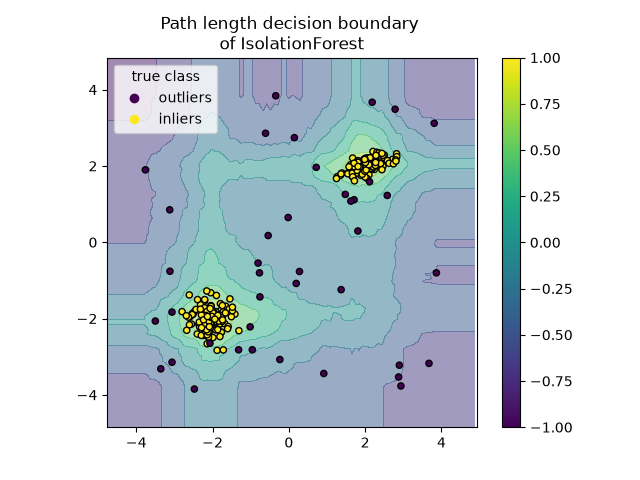

In [ ]:
# This is where we train the model
frequency = Pipeline([
    ("count", CountEncoder(cols=NOMINAL)),
    ("log_scale", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))
])

prepare = ColumnTransformer([
    ("frequency", frequency, NOMINAL),
    ("numeric", "passthrough", NUMERIC) # dollar amounts and item counts are used normally, this is because we do want the model to treat these as regular numbers not categorical values
],
verbose_feature_names_out=False).set_output(transform="pandas")

model = Pipeline([
    ("prepare", prepare),
    ("isolation_forest", IsolationForest(n_estimators=200, contamination=REVIEW_SHARE, random_state=RANDOM_STATE))
])

# .fit() is where the model learns from the data that we have.
model.fit(claims[FEATURES])


Saving the model!

In [ ]:
import joblib

joblib.dump(model, "path/to/model.joblib")

In [ ]:
claims["anomaly_score"] = -model.decision_function(claims[FEATURES])
claims["flagged"] =model.predict(claims[FEATURES]) == -1

print(f"Flagged {claims["flagged"].sum():,} of {len(claims):,} claims ({claims["flagged"].mean():.1%}) for review")

In [ ]:
LABELS = {
    "CLAIM_DOLLAR_AMOUNT_PAID": "Paid ($)",
    "CLAIM_SERVICES_FULL_SUBMISSION": "Billed by doctor ($)",
    "n_lines": "Line items",
    "n_services": "Units of service",
    "n_examinations": "Examinations",
    "PATIENT_ID": "Claims for this patient",
    "DOCTOR_ID": "Claims by this doctor",
    "PRACTICE_ID": "Claims by this practice",
    "PRIMARY_EXAMINATION_CODE": "Claims with this main examination"
}

readable = claims[NUMERIC].join(frequency_counts)

comparison = readable.groupby(claims["flagged"]).median().T.loc[FEATURES]
comparison.columns = ["Typical claim", "Flagged claim"]
comparison.rename(index=LABELS).round(1)

## Which doctors to be looked at first?

In [ ]:
by_doctor = claims.groupby("DOCTOR_ID").agg(
    claims=("flagged", "size"),
    flagged_claims=("flagged", "sum")
)

by_doctor["pct_flagged"] = (100 * by_doctor["flagged_claims"] / by_doctor["claims"]).round(1)

top_doctors = by_doctor.sort_values(["flagged_claims", "pct_flagged"], ascending=False).head(10)
top_doctors.rename(columns={"claims": "Claims", "flagged_claims": "Flagged claims", "pct_flagged": "% flagged"})